# Exploratory Data Analysis: Stockholm Bus Line 4

This notebook explores the January 2024 modelling dataset before model training. The analysis focuses on temporal delay patterns, spatial variation along the route, recent-delay persistence, and the presence of extreme observations.

The predictive models and final temporal train/validation/test evaluation are implemented separately in ``03_model_comparison.ipynb``.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# ============================================================
# Data loading
# ============================================================

if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

PROCESSED_DIR = (
    '/content/drive/MyDrive/'
    'AH2179_AI_Transport_Project/data/processed'
)

MASTER_FILE = os.path.join(
    PROCESSED_DIR,
    'master_feature_table_line4.parquet'
)

SPATIAL_FILE = os.path.join(
    PROCESSED_DIR,
    'line4_osm_segment_features.parquet'
)

df_master = pd.read_parquet(
    MASTER_FILE
)

df_features = pd.read_parquet(
    SPATIAL_FILE
)

# Attach stop names to the stop-level modelling table.
stop_name_map = (
    df_features
    .set_index(
        ['direction_id', 'observed_stop_id']
    )['to_name']
    .to_dict()
)

df_master['stop_name'] = (
    df_master
    .set_index(
        ['direction_id', 'observed_stop_id']
    )
    .index
    .map(stop_name_map)
)

# Convert arrival delay from seconds to minutes for visualization.
df_master['delay_min'] = (
    df_master['observed_arrival_delay']
    / 60.0
)

df_master['hour'] = (
    df_master['scheduled_arrival_time_sfm']
    // 3600
).astype(int)

print("=== Line 4 modelling dataset ===")
print(f"Observations: {len(df_master):,}")
print(
    "Service period:",
    df_master['date'].min(),
    "-",
    df_master['date'].max()
)
print(
    "Directed stop-to-stop segments:",
    len(df_features)
)
print(
    "Unique trip IDs:",
    f"{df_master['trip_id'].nunique():,}"
)

Mounted at /content/drive
=== Line 4 modelling dataset ===
Observations: 195,524
Service period: 20240101 - 20240131
Directed stop-to-stop segments: 48
Unique trip IDs: 901


In [2]:
# ============================================================
# Dataset overview and basic quality checks
# ============================================================

print("=== Missing values in modelling variables ===")

quality_columns = [
    'observed_arrival_delay',
    'delay_lag_1',
    'delay_lag_2',
    'scheduled_arrival_time_sfm',
    'direction_id',
    'stop_sequence',
    'network_length_m',
    'num_traffic_signals',
    'num_intersections',
    'bus_lane_ratio',
    'has_bus_priority'
]

missing_summary = (
    df_master[quality_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(missing_summary)

print("\n=== Target summary: arrival delay in seconds ===")

print(
    df_master['observed_arrival_delay']
    .describe(
        percentiles=[
            0.50,
            0.90,
            0.95,
            0.99,
            0.999
        ]
    )
    .round(2)
)

=== Missing values in modelling variables ===
observed_arrival_delay        0
delay_lag_1                   0
delay_lag_2                   0
scheduled_arrival_time_sfm    0
direction_id                  0
stop_sequence                 0
network_length_m              0
num_traffic_signals           0
num_intersections             0
bus_lane_ratio                0
has_bus_priority              0
dtype: int64

=== Target summary: arrival delay in seconds ===
count    195524.00
mean        155.63
std         262.00
min        -588.00
50%          93.00
90%         407.00
95%         571.00
99%        1044.77
99.9%      2527.82
max        7423.00
Name: observed_arrival_delay, dtype: float64


## Spatiotemporal Delay Patterns

The heatmaps below summarize the average arrival delay across stops and hours of the day for both travel directions. They provide a descriptive view of how delay patterns vary over time and along the Line 4 corridor.

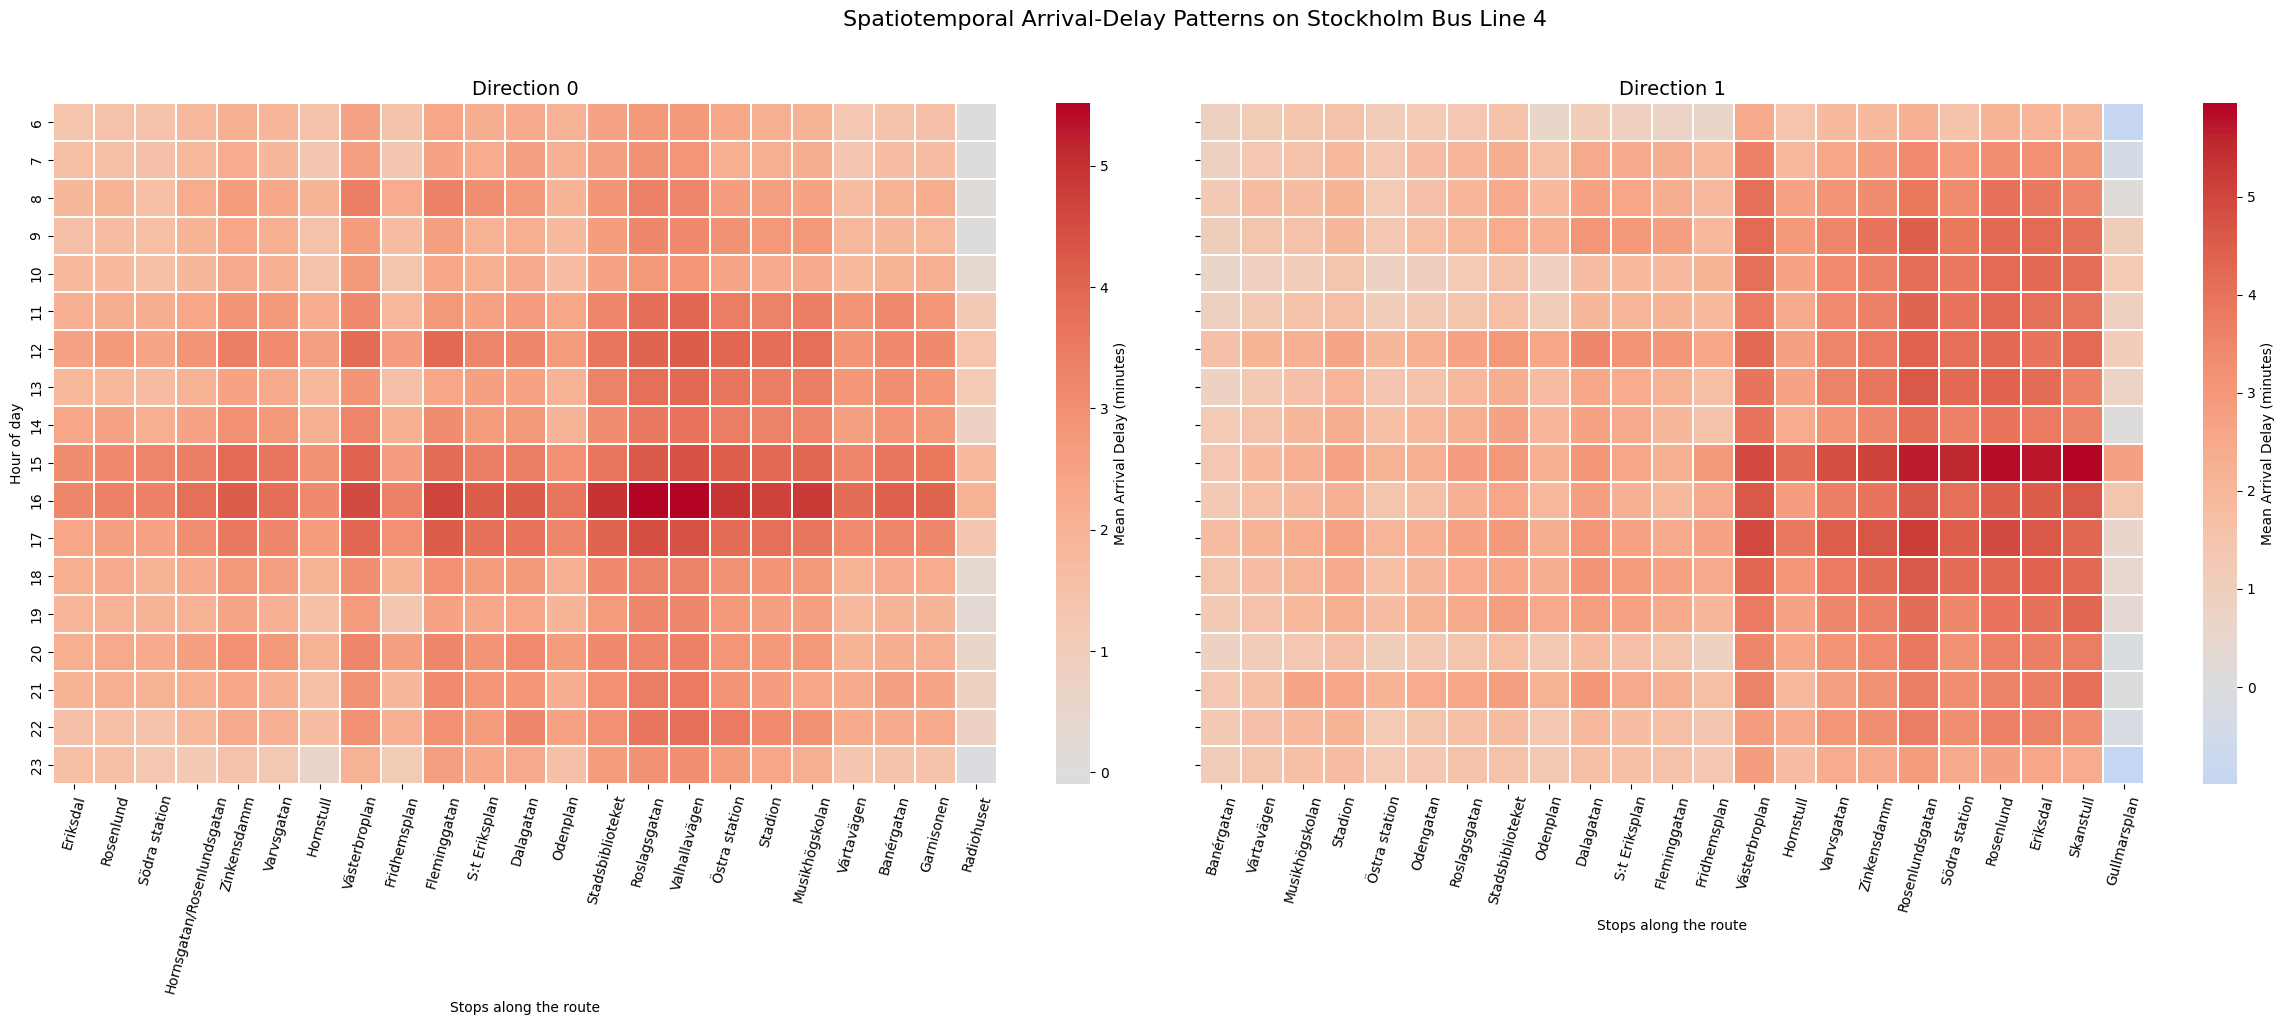

Saved: /content/drive/MyDrive/AH2179_AI_Transport_Project/data/processed/line4_spatiotemporal_delay_heatmap.png


In [5]:
# ============================================================
# Spatiotemporal delay patterns by route direction
# ============================================================

# Restrict the visualization to the main operating period.
df_heatmap = df_master[
    (df_master['hour'] >= 6)
    &
    (df_master['hour'] <= 23)
].copy()

fig, axes = plt.subplots(
    1,
    2,
    figsize=(24, 10),
    sharey=True
)

direction_titles = {
    0: "Direction 0",
    1: "Direction 1"
}

for plot_index, direction_id in enumerate([0, 1]):

    ax = axes[plot_index]

    subset = df_heatmap[
        df_heatmap['direction_id'] == direction_id
    ].copy()

    # Preserve the physical order of stops along the route.
    stop_order = (
        subset
        .groupby('stop_name')['stop_sequence']
        .mean()
        .sort_values()
        .index
        .tolist()
    )

    delay_matrix = (
        subset
        .pivot_table(
            index='hour',
            columns='stop_name',
            values='delay_min',
            aggfunc='mean'
        )
        .reindex(columns=stop_order)
    )

    sns.heatmap(
        delay_matrix,
        ax=ax,
        cmap='coolwarm',
        center=0,
        cbar_kws={
            'label': 'Mean Arrival Delay (minutes)'
        },
        linewidths=0.3
    )

    ax.set_title(
        direction_titles[direction_id],
        fontsize=14
    )

    ax.set_xlabel(
        "Stops along the route"
    )

    ax.set_ylabel(
        "Hour of day"
        if plot_index == 0
        else ""
    )

    ax.tick_params(
        axis='x',
        rotation=75
    )

plt.suptitle(
    "Spatiotemporal Arrival-Delay Patterns on Stockholm Bus Line 4",
    fontsize=16,
    y=1.02
)

plt.tight_layout()

HEATMAP_FILE = os.path.join(
    PROCESSED_DIR,
    'line4_spatiotemporal_delay_heatmap.png'
)

plt.savefig(
    HEATMAP_FILE,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(
    "Saved:",
    HEATMAP_FILE
)

## Example Trip-Level Delay Trajectories

To illustrate how delay evolves along individual bus runs, several consecutive weekday trips around the afternoon peak are selected from one service day. This visualization is descriptive and is not used to infer causal effects of particular road segments.

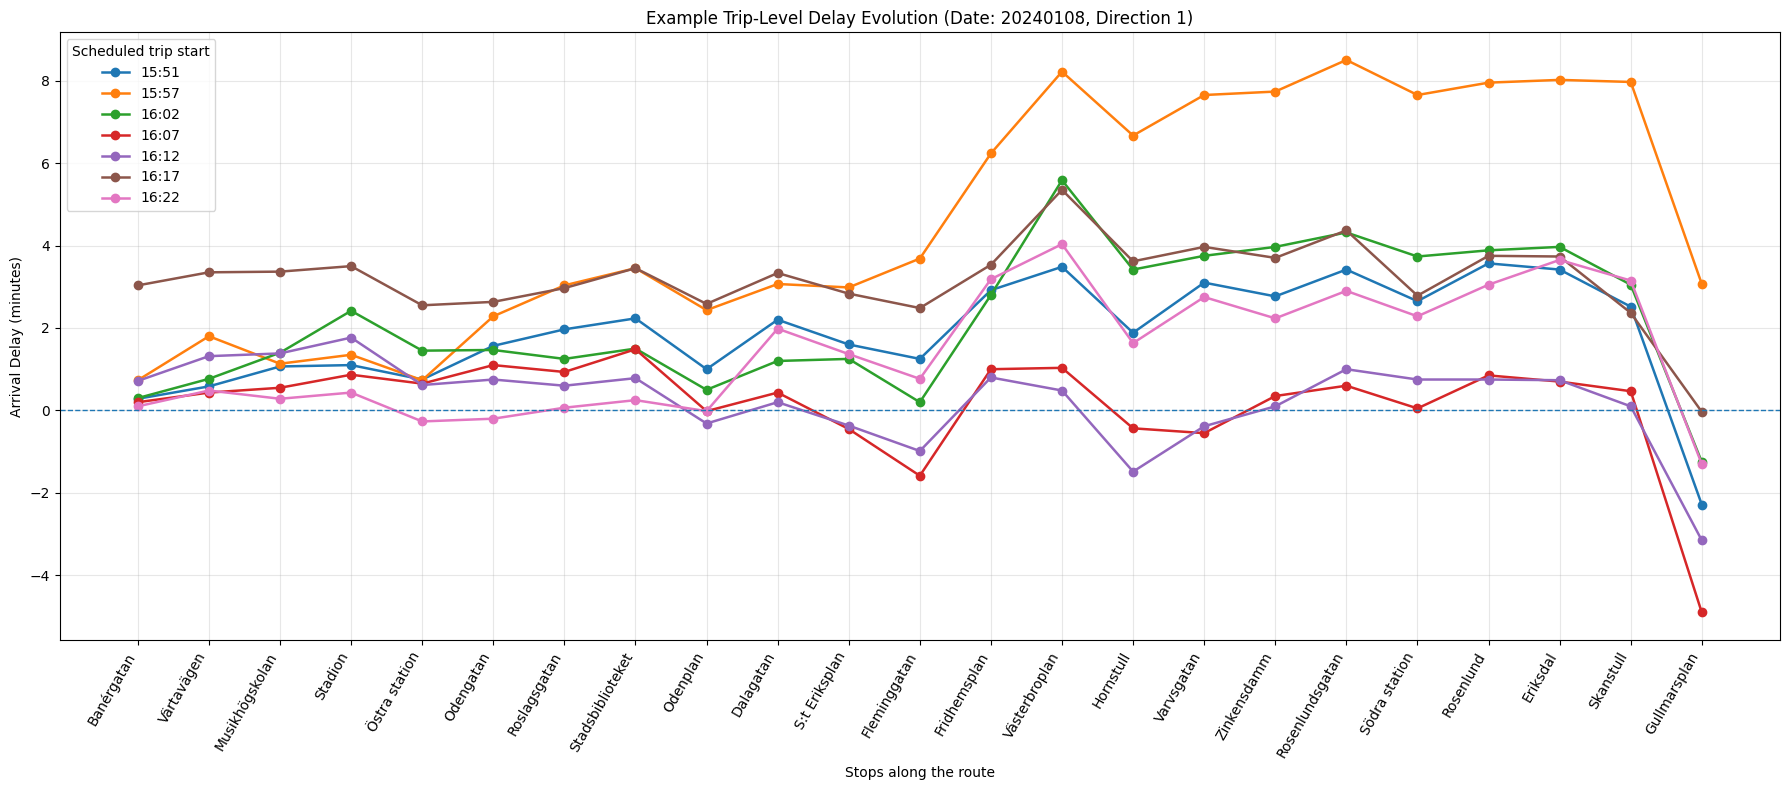

Saved: /content/drive/MyDrive/AH2179_AI_Transport_Project/data/processed/line4_example_trip_delay_trajectories.png


In [3]:
# ============================================================
# Example trip-level delay trajectories
# ============================================================

target_direction = 1

direction_data = df_master[
    (df_master['direction_id'] == target_direction)
    &
    (df_master['is_weekend'] == 0)
].copy()

# Select the weekday with the largest number of recorded trips.
sample_date = (
    direction_data
    .groupby('date')
    ['trip_id']
    .nunique()
    .idxmax()
)

sample_day = direction_data[
    direction_data['date']
    == sample_date
].copy()

# Identify trips beginning around the afternoon peak.
trip_start_times = (
    sample_day
    .groupby('trip_id')
    ['scheduled_arrival_time_sfm']
    .min()
)

selected_trip_ids = (
    trip_start_times[
        (trip_start_times >= 15.8 * 3600)
        &
        (trip_start_times <= 16.75 * 3600)
    ]
    .sort_values()
    .head(7)
    .index
    .tolist()
)

trip_data = (
    sample_day[
        sample_day['trip_id']
        .isin(selected_trip_ids)
    ]
    .sort_values(
        [
            'trip_id',
            'stop_sequence'
        ]
    )
)

stop_order = (
    trip_data
    .groupby('stop_name')
    ['stop_sequence']
    .mean()
    .sort_values()
    .index
    .tolist()
)

stop_to_index = {
    stop_name: i
    for i, stop_name
    in enumerate(stop_order)
}

trip_data['route_index'] = (
    trip_data['stop_name']
    .map(stop_to_index)
)

plt.figure(
    figsize=(18, 8)
)

for trip_id in selected_trip_ids:

    trip = (
        trip_data[
            trip_data['trip_id']
            == trip_id
        ]
        .sort_values(
            'route_index'
        )
    )

    if trip.empty:
        continue

    start_time = (
        trip['scheduled_arrival_time_sfm']
        .iloc[0]
    )

    departure_label = (
        f"{int(start_time // 3600):02d}:"
        f"{int((start_time % 3600) // 60):02d}"
    )

    plt.plot(
        trip['route_index'],
        trip['delay_min'],
        marker='o',
        linewidth=1.8,
        label=departure_label
    )

plt.axhline(
    0,
    linestyle='--',
    linewidth=1
)

plt.title(
    f"Example Trip-Level Delay Evolution "
    f"(Date: {sample_date}, Direction {target_direction})"
)

plt.xlabel(
    "Stops along the route"
)

plt.ylabel(
    "Arrival Delay (minutes)"
)

plt.xticks(
    range(len(stop_order)),
    stop_order,
    rotation=60,
    ha='right'
)

plt.grid(
    alpha=0.3
)

plt.legend(
    title="Scheduled trip start"
)

plt.tight_layout()

TRAJECTORY_FILE = os.path.join(
    PROCESSED_DIR,
    'line4_example_trip_delay_trajectories.png'
)

plt.savefig(
    TRAJECTORY_FILE,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(
    "Saved:",
    TRAJECTORY_FILE
)

## Delay Persistence

Recent delay history is expected to be one of the strongest predictors of next-stop arrival delay. The following correlation analysis examines the relationship between the current observed delay and lagged delays from preceding stops.

Correlation between current delay and previous-stop delay: 0.97
Correlation between current delay and two-stop lag: 0.9567


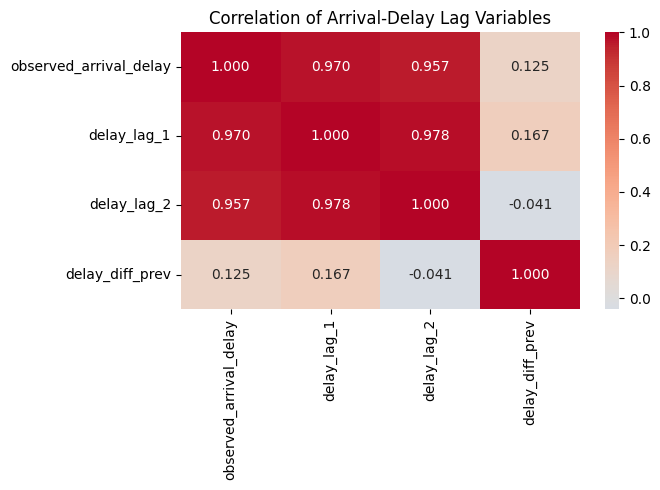

In [4]:
# ============================================================
# Delay persistence across consecutive stops
# ============================================================

persistence_variables = [
    'observed_arrival_delay',
    'delay_lag_1',
    'delay_lag_2',
    'delay_diff_prev'
]

correlation_matrix = (
    df_master[
        persistence_variables
    ]
    .corr()
)

print(
    "Correlation between current delay and previous-stop delay:",
    round(
        correlation_matrix.loc[
            'observed_arrival_delay',
            'delay_lag_1'
        ],
        4
    )
)

print(
    "Correlation between current delay and two-stop lag:",
    round(
        correlation_matrix.loc[
            'observed_arrival_delay',
            'delay_lag_2'
        ],
        4
    )
)

plt.figure(
    figsize=(7, 5)
)

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0
)

plt.title(
    "Correlation of Arrival-Delay Lag Variables"
)

plt.tight_layout()

plt.show()

## Arrival-Delay Distribution

The distribution of observed arrival delays is examined to understand the typical operating range and the presence of rare extreme observations. Extreme values are retained in the dataset because they may represent genuine disruption events and are relevant for evaluating model robustness.

=== Arrival-delay distribution ===
count    195524.00
mean        155.63
std         262.00
min        -588.00
50%          93.00
90%         407.00
95%         571.00
99%        1044.77
99.9%      2527.82
max        7423.00
Name: observed_arrival_delay, dtype: float64

Observations with |delay| > 10 minutes: 8,676
Share of observations with |delay| > 10 minutes: 4.44%


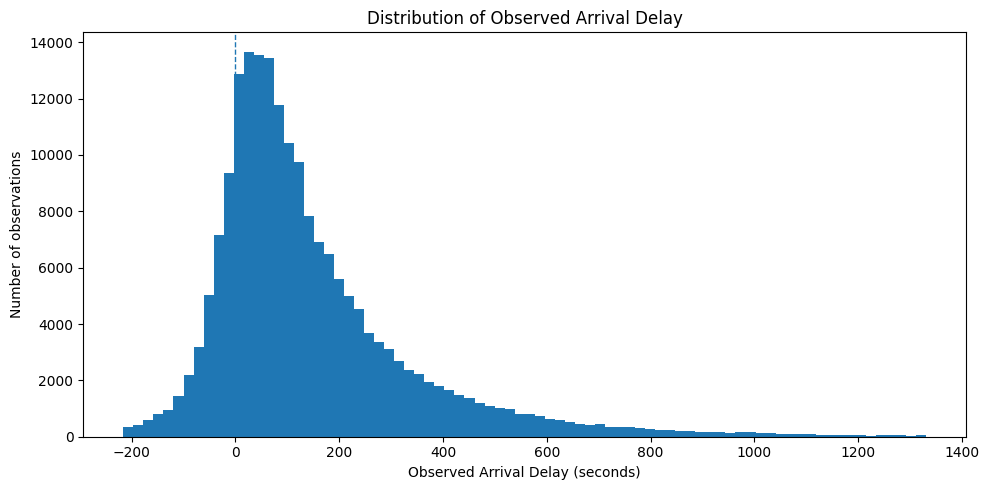


Saved: /content/drive/MyDrive/AH2179_AI_Transport_Project/data/processed/line4_arrival_delay_distribution.png


In [6]:
# ============================================================
# Arrival-delay distribution and extreme observations
# ============================================================

delay = (
    df_master['observed_arrival_delay']
    .dropna()
)

print("=== Arrival-delay distribution ===")

print(
    delay.describe(
        percentiles=[
            0.50,
            0.90,
            0.95,
            0.99,
            0.999
        ]
    ).round(2)
)

extreme_threshold = 600  # 10 minutes

extreme_count = (
    np.abs(delay) > extreme_threshold
).sum()

extreme_share = (
    extreme_count
    / len(delay)
    * 100
)

print(
    "\nObservations with |delay| > 10 minutes:",
    f"{extreme_count:,}"
)

print(
    "Share of observations with |delay| > 10 minutes:",
    f"{extreme_share:.2f}%"
)

# Limit the displayed range only for visualization.
# All observations, including extreme delays, remain in the dataset.
lower_bound = delay.quantile(0.005)
upper_bound = delay.quantile(0.995)

plt.figure(
    figsize=(10, 5)
)

plt.hist(
    delay[
        (delay >= lower_bound)
        &
        (delay <= upper_bound)
    ],
    bins=80
)

plt.axvline(
    0,
    linestyle='--',
    linewidth=1
)

plt.xlabel(
    "Observed Arrival Delay (seconds)"
)

plt.ylabel(
    "Number of observations"
)

plt.title(
    "Distribution of Observed Arrival Delay"
)

plt.tight_layout()

DISTRIBUTION_FILE = os.path.join(
    PROCESSED_DIR,
    'line4_arrival_delay_distribution.png'
)

plt.savefig(
    DISTRIBUTION_FILE,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print(
    "\nSaved:",
    DISTRIBUTION_FILE
)